# Анализ повторных покупок и сегментация клиентов интернет-магазина

## Введение

Цель проекта — на реальных транзакционных данных интернет-магазина показать полный аналитический цикл: от очистки данных до бизнес-выводов и baseline ML-модели, которая прогнозирует вероятность повторной покупки.

В качестве источника использован датасет **UCI Online Retail**: это история заказов британского онлайн-ритейлера за период с декабря 2010 года по декабрь 2011 года.

После очистки в работе осталось **392,692** строк, **4,338** клиентов и **18,532** заказов. Совокупная выручка очищенной выборки составила **8,887,208.89**.

## Описание данных

Основные поля датасета:

- `InvoiceNo` — номер транзакции; если начинается с `C`, это отмена заказа.
- `StockCode` — идентификатор товара.
- `Description` — название товара.
- `Quantity` — количество единиц товара в строке заказа.
- `InvoiceDate` — дата и время покупки.
- `UnitPrice` — цена за единицу товара.
- `CustomerID` — идентификатор клиента.
- `Country` — страна клиента.

Для задач сегментации, retention и ML нам критично сохранять только строки, которые можно надежно связать с клиентом и реальной покупкой. Поэтому этап очистки здесь напрямую влияет на качество последующих выводов.

## Загрузка и первичный осмотр данных

Сначала загрузим сырые данные, посмотрим на структуру и оценим качество: пропуски, дубликаты и аномальные значения.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

from IPython.display import display
import pandas as pd

from retail_repeat_analysis import (
    build_cohort_retention,
    build_ml_artifacts,
    build_order_table,
    calculate_overview_metrics,
    clean_transactions,
    compute_customer_concentration,
    compute_rfm_table,
    configure_plotting,
    load_transactions,
    plot_cohort_heatmap,
    plot_customer_concentration,
    plot_feature_importance,
    plot_model_roc_curves,
    plot_monthly_active_customers,
    plot_monthly_revenue,
    plot_order_value_distribution,
    plot_rfm_segments,
    plot_top_countries,
)

configure_plotting()
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "online_retail.csv"

In [2]:
raw_df = load_transactions(RAW_DATA_PATH)
display(raw_df.head())

raw_quality = pd.DataFrame(
    {
        "Признак": raw_df.columns,
        "Тип данных": raw_df.dtypes.astype(str).values,
        "Пропуски": raw_df.isna().sum().values,
        "Доля пропусков, %": (raw_df.isna().mean() * 100).round(2).values,
    }
)
display(raw_quality)

pd.DataFrame(
    {
        "Метрика": [
            "Строк в сыром датасете",
            "Дубликаты",
            "Строк без CustomerID",
            "Отмененные заказы",
            "Строк с Quantity <= 0",
            "Строк с UnitPrice <= 0",
        ],
        "Значение": [
            len(raw_df),
            int(raw_df.duplicated().sum()),
            int(raw_df["CustomerID"].isna().sum()),
            int(raw_df["InvoiceNo"].astype(str).str.startswith("C").sum()),
            int((raw_df["Quantity"] <= 0).sum()),
            int((raw_df["UnitPrice"] <= 0).sum()),
        ],
    }
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,Признак,Тип данных,Пропуски,"Доля пропусков, %"
0,InvoiceNo,str,0,0.00
1,StockCode,str,0,0.00
2,Description,str,1454,0.27
3,Quantity,int64,0,0.00
4,InvoiceDate,datetime64[us],0,0.00
5,UnitPrice,float64,0,0.00
6,CustomerID,float64,135080,24.93
7,Country,str,0,0.00


,Метрика,Значение
0,Строк в сыром датасете,541909
1,Дубликаты,5268
2,Строк без CustomerID,135080
3,Отмененные заказы,9288
4,Строк с Quantity <= 0,10624
5,Строк с UnitPrice <= 0,2517


## Очистка данных

Логика очистки:

1. Удалить строки без `CustomerID`, потому что их нельзя использовать в клиентской аналитике.
2. Исключить отмененные заказы.
3. Удалить строки с неположительным количеством товара и неположительной ценой.
4. Удалить полные дубликаты.

Важно: мы не удаляем данные "по привычке". Каждый шаг нужен либо для сохранения корректной логики транзакций, либо для предотвращения искажений в расчетах выручки, частоты и retention.

In [3]:
clean_df, cleaning_summary = clean_transactions(raw_df)
order_df = build_order_table(clean_df)
overview_metrics = calculate_overview_metrics(clean_df, order_df)

display(cleaning_summary)
display(overview_metrics)
clean_df.head()

,Этап,Строк до,Строк после,Удалено строк,"Доля от исходного датасета, %"
0,Удаление строк без CustomerID,541909,406829,135080,24.93
1,Удаление отмененных заказов,406829,397924,8905,1.64
2,Удаление строк с неположительными Quantity и U...,397924,397884,40,0.01
3,Удаление полных дубликатов,397884,392692,5192,0.96


,Метрика,Значение
0,Период данных,01.12.2010 - 09.12.2011
1,Строк после очистки,392692
2,Уникальные клиенты,4338
3,Уникальные заказы,18532
4,Общая выручка,8887208.89
5,Средний чек,479.56
6,Медианный чек,302.57
7,Среднее число заказов на клиента,4.27
8,Медианное число заказов на клиента,2.0
9,Доля выручки от топ-10% клиентов,0.6141


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,InvoiceMonth,InvoiceDay
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,2010-12-01
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,2010-12-01
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,2010-12-01
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,2010-12-01
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,2010-12-01


## Исследовательский анализ данных

Ниже собраны ключевые бизнес-метрики: динамика выручки, активность клиентской базы, распределение чеков, география продаж и концентрация выручки по клиентам.

In [4]:
top_products = (
    clean_df.groupby("Description", as_index=False)["Revenue"]
    .sum()
    .sort_values("Revenue", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top_countries = (
    clean_df.groupby("Country", as_index=False)
    .agg(Выручка=("Revenue", "sum"), Заказы=("InvoiceNo", "nunique"), Клиенты=("CustomerID", "nunique"))
    .sort_values("Выручка", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(top_countries)
display(top_products)

,Country,Выручка,Заказы,Клиенты
0,United Kingdom,7285024.644,16646,3920
1,Netherlands,285446.340,94,9
2,EIRE,265262.460,260,3
3,Germany,228678.400,457,94
4,France,208934.310,389,87
5,Australia,138453.810,57,9
6,Spain,61558.560,90,30
7,Switzerland,56443.950,51,21
8,Belgium,41196.340,98,25
9,Sweden,38367.830,36,8


,Description,Revenue
0,"PAPER CRAFT , LITTLE BIRDIE",168469.60
1,REGENCY CAKESTAND 3 TIER,142264.75
2,WHITE HANGING HEART T-LIGHT HOLDER,100392.10
3,JUMBO BAG RED RETROSPOT,85040.54
4,MEDIUM CERAMIC TOP STORAGE JAR,81416.73
5,POSTAGE,77803.96
6,PARTY BUNTING,68785.23
7,ASSORTED COLOUR BIRD ORNAMENT,56413.03
8,Manual,53419.93
9,RABBIT NIGHT LIGHT,51251.24


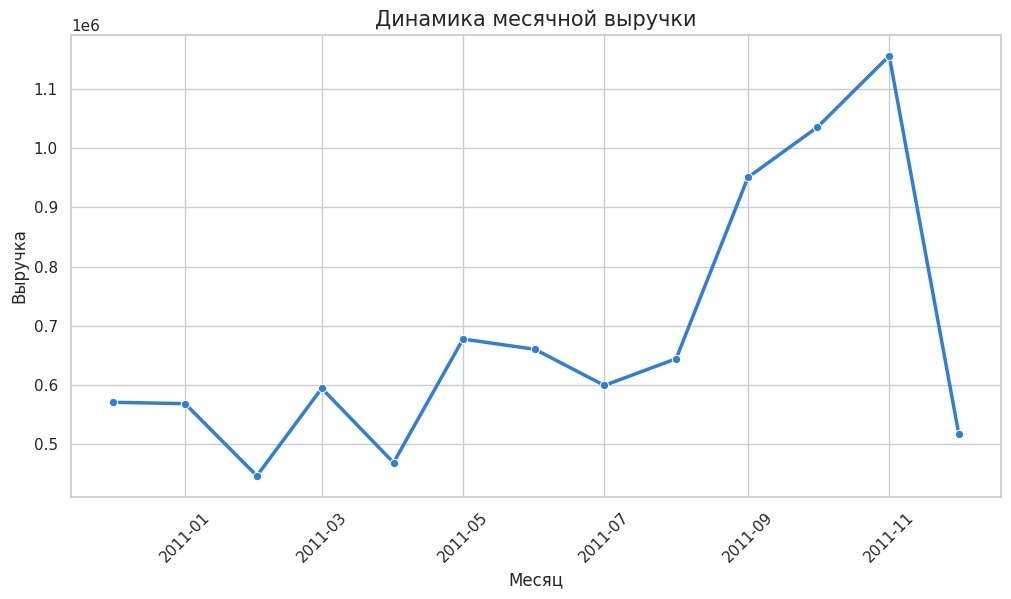

In [5]:
plot_monthly_revenue(clean_df);

**Интерпретация:** выручка растет к осени и достигает пика в ноябре. Для e-commerce это выглядит как сочетание сезонного эффекта и усиления активности перед праздничным периодом.

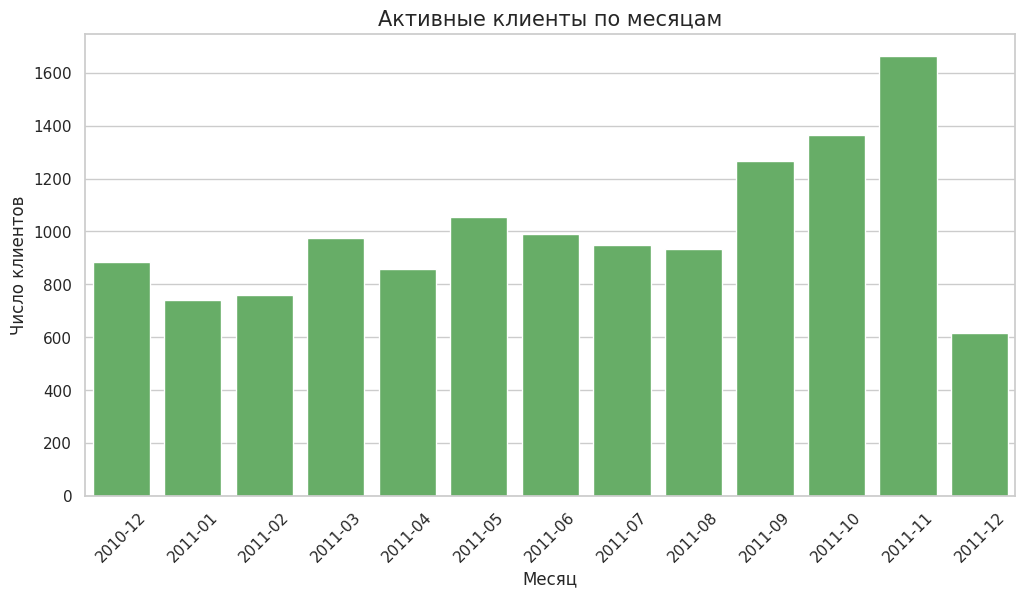

In [6]:
plot_monthly_active_customers(clean_df);

**Интерпретация:** вместе с выручкой растет и число активных клиентов. Значит, рост объясняется не только более дорогими корзинами, но и расширением активной базы.

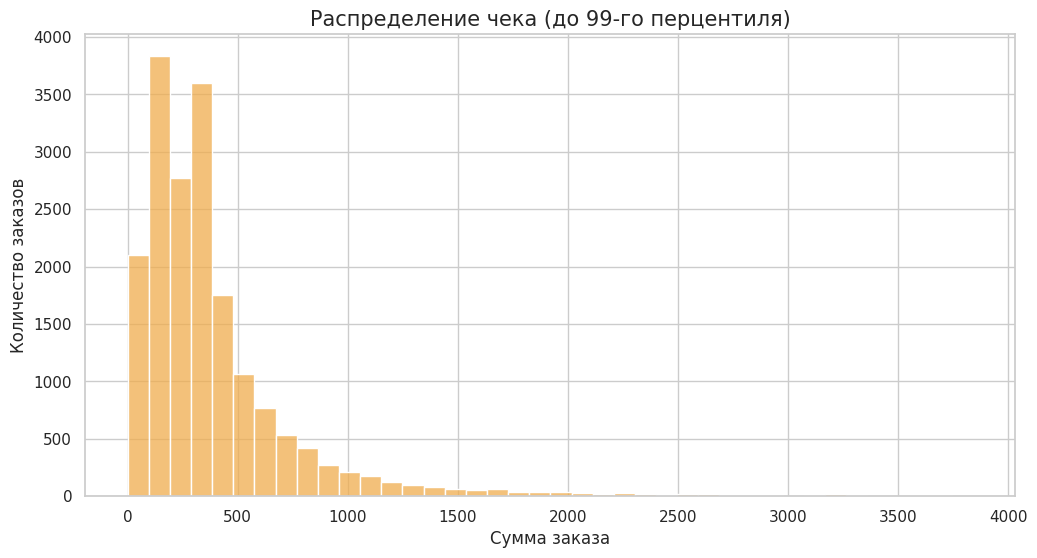

In [7]:
plot_order_value_distribution(order_df);

**Интерпретация:** распределение чеков сильно скошено вправо: большинство заказов имеют умеренный размер, но есть небольшой хвост крупных покупок. Поэтому для описания клиентского поведения полезно смотреть и на средние, и на медианные значения.

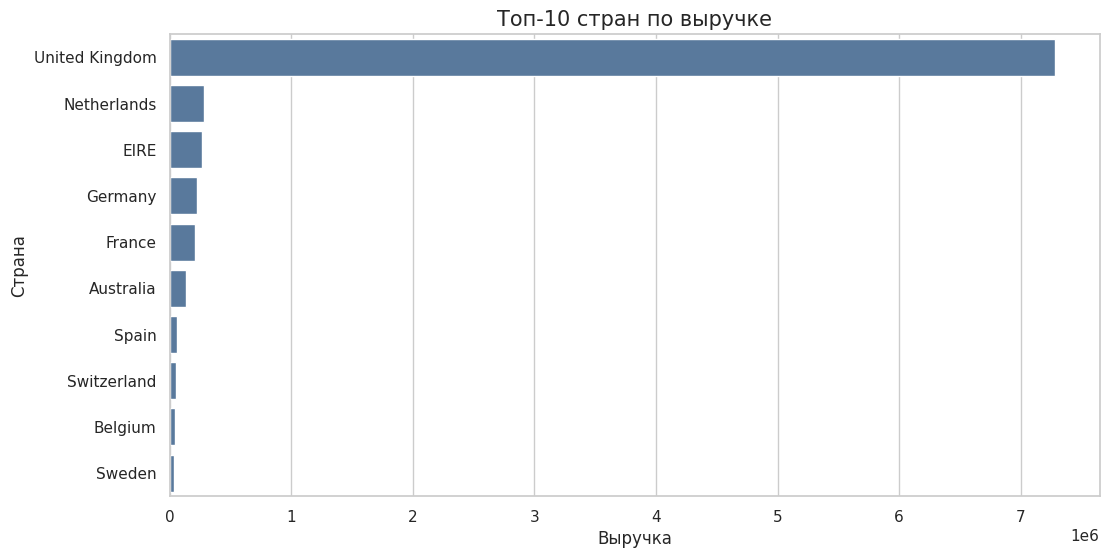

In [8]:
plot_top_countries(clean_df);

**Интерпретация:** продажи сильно концентрируются в Великобритании. Это главный рынок, а зарубежные страны работают как заметное, но существенно меньшее дополнение к основной выручке.

Крупнейшая зарубежная страна по выручке: **Netherlands**.

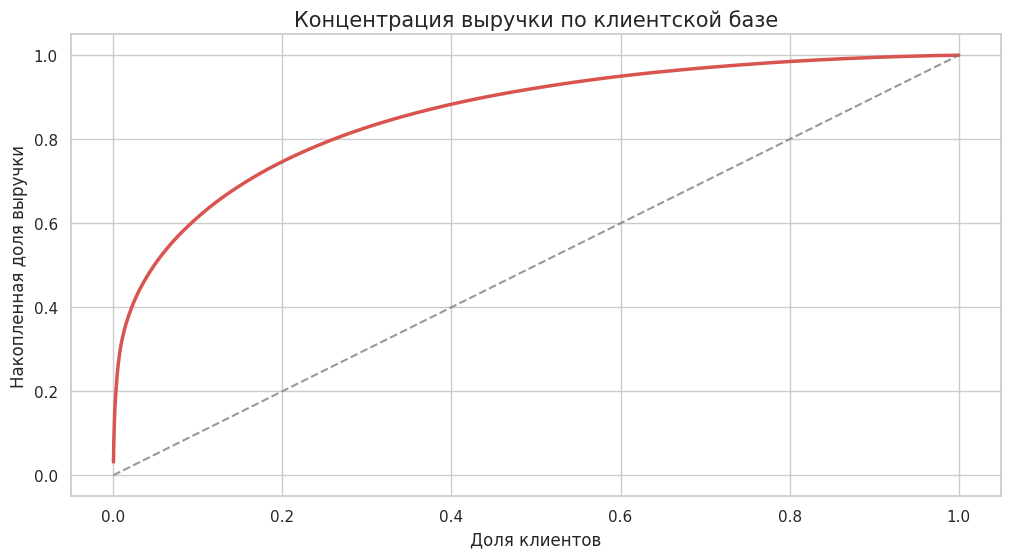

In [9]:
concentration_df = compute_customer_concentration(clean_df)
plot_customer_concentration(concentration_df);

**Интерпретация:** выручка распределена неравномерно. Верхняя часть клиентской базы формирует большую долю оборота, поэтому CRM-стратегия должна быть дифференцированной: для ценных клиентов важнее удержание, а для широкой базы — реактивация и повторная конверсия.

## RFM-сегментация клиентов

RFM-модель описывает клиента через три измерения:

- `Recency` — как давно была последняя покупка;
- `Frequency` — как часто клиент покупает;
- `Monetary` — сколько денег клиент приносит.

Для каждой метрики рассчитаны квантильные оценки от 1 до 5, после чего клиенты отнесены к бизнес-сегментам: чемпионы, лояльные, потенциально лояльные, новые, обещающие, требующие внимания, в зоне риска и потерянные.

In [10]:
rfm_df, rfm_summary = compute_rfm_table(clean_df)
display(rfm_df.head())
display(rfm_summary)

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,1,77183.60,1,1,5,115,Потерянные
1,12347,2,7,4310.00,5,5,5,555,Чемпионы
2,12348,75,4,1797.24,2,4,4,244,В зоне риска
3,12349,19,1,1757.55,4,1,4,414,Обещающие
4,12350,310,1,334.40,1,1,2,112,Потерянные


,Segment,Клиенты,Выручка,Средняя_выручка_на_клиента,Средняя_частота,Средняя_давность_дней,"Доля клиентов, %","Доля выручки, %"
0,Чемпионы,1121,5857798.930,5225.511980,10.051740,12.995540,25.84,65.91
1,В зоне риска,661,823912.441,1246.463602,3.413011,150.642965,15.24,9.27
2,Лояльные,329,807776.941,2455.249061,5.723404,48.969605,7.58,9.09
3,Потерянные,1262,692492.632,548.726333,1.282884,192.022979,29.09,7.79
4,Потенциально лояльные,477,496163.250,1040.174528,2.014675,16.624738,11.00,5.58
5,Требуют внимания,351,158607.280,451.872593,1.162393,52.504274,8.09,1.78
6,Обещающие,95,34286.480,360.910316,1.000000,23.042105,2.19,0.39
7,Новые,42,16170.940,385.022381,1.000000,6.857143,0.97,0.18


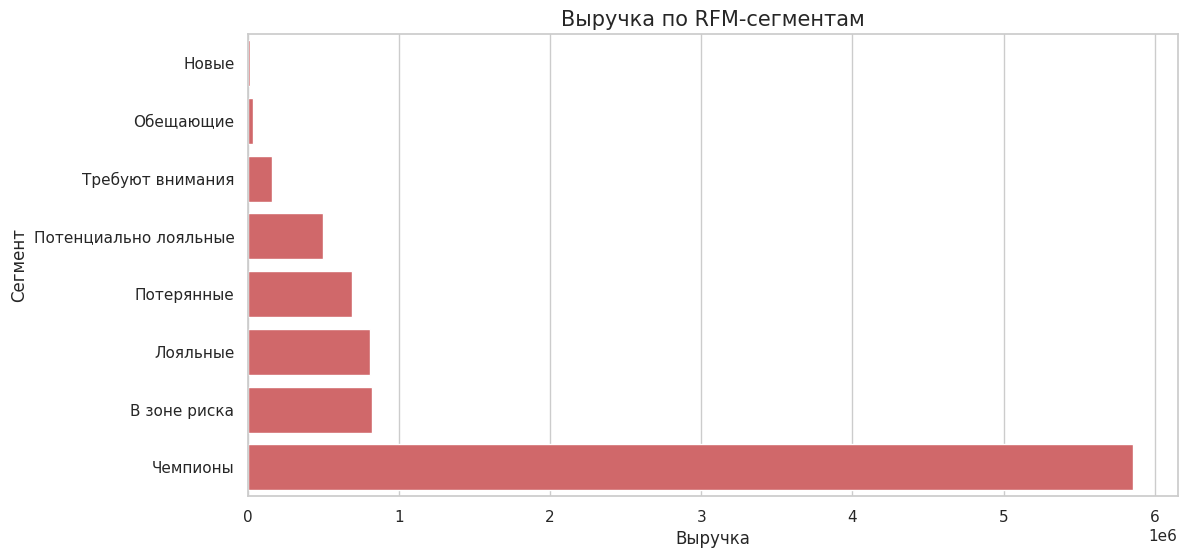

In [11]:
plot_rfm_segments(rfm_summary);

**Интерпретация:** RFM-сегментация помогает отделить действительно ценных клиентов от клиентов с единичными покупками. Это удобно не только для аналитики, но и для практического CRM: разные сегменты требуют разных коммуникаций и разных бюджетов.

## Когортный анализ и retention

Когорта — это группа клиентов, объединенная по месяцу первой покупки. Retention показывает, какая доля клиентов из этой когорты возвращается в следующие месяцы.

Средний retention в первый месяц после первой покупки по наблюдаемым когортам составил примерно **20.6%**. Лучшая когорта по retention первого месяца — **2010-12** с уровнем около **36.6%**.

Для последних когорт данные нужно трактовать аккуратно: у них меньше времени на "дожитие", поэтому правый край матрицы неизбежно неполон.

In [12]:
cohort_counts, retention = build_cohort_retention(clean_df)
display(retention.round(3))

CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2010-12,1.0,0.366,0.323,0.384,0.363,0.398,0.363,0.349,0.354,0.395,0.374,0.503,0.266
2011-01,1.0,0.221,0.266,0.230,0.321,0.288,0.247,0.242,0.300,0.326,0.365,0.118,NaN
2011-02,1.0,0.187,0.187,0.284,0.271,0.247,0.253,0.279,0.247,0.305,0.068,NaN,NaN
2011-03,1.0,0.150,0.252,0.199,0.223,0.168,0.268,0.230,0.279,0.086,NaN,NaN,NaN
2011-04,1.0,0.213,0.203,0.210,0.197,0.227,0.217,0.260,0.073,NaN,NaN,NaN,NaN
2011-05,1.0,0.190,0.173,0.173,0.208,0.232,0.264,0.095,NaN,NaN,NaN,NaN,NaN
2011-06,1.0,0.174,0.157,0.264,0.231,0.335,0.095,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,1.0,0.181,0.207,0.223,0.271,0.112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,1.0,0.207,0.249,0.243,0.124,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


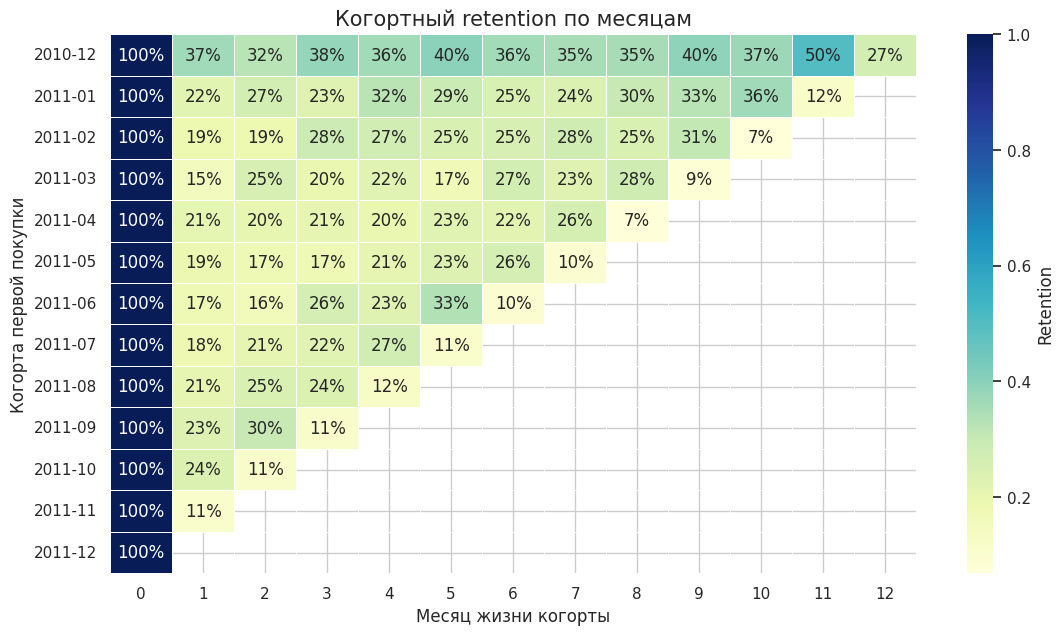

In [13]:
plot_cohort_heatmap(retention);

**Интерпретация:** retention подтверждает, что повторные покупки есть, но они не одинаковы для всех когорт. Это важный сигнал для маркетинга и продуктовой коммуникации: качество привлечения клиентов и опыт первой покупки заметно влияют на возврат.

## Построение модели прогноза повторной покупки

ML-задача сформулирована так: по истории клиента на момент "среза" предсказать, совершит ли он хотя бы одну повторную покупку в следующие 90 дней.

Чтобы избежать утечки:

- признаки считаются только по прошлой истории на дату среза;
- выборка строится из нескольких ежемесячных снапшотов;
- тестом служит самый поздний доступный снапшот;
- горизонт прогноза фиксирован и одинаков для всех наблюдений.

В качестве baseline-моделей сравниваются:

- логистическая регрессия;
- Random Forest.

Лучшая модель по ROC-AUC: **Random Forest** с результатом **0.775**.

In [14]:
ml_artifacts = build_ml_artifacts(clean_df, order_df)
display(ml_artifacts["metrics_df"])
display(ml_artifacts["feature_importance"].head(10))

,Модель,ROC-AUC,F1,Precision,Recall
0,Random Forest,0.7746,0.6978,0.7821,0.6298
1,Логистическая регрессия,0.7472,0.6708,0.7845,0.5858


,Признак,Важность
0,num__frequency_orders,0.142824
1,num__active_months,0.139909
2,num__total_units,0.139748
3,num__monetary_total,0.133168
4,num__recency_days,0.087557
5,num__unique_products,0.075806
6,num__avg_days_between_orders,0.068361
7,num__max_order_value,0.065125
8,num__avg_order_value,0.051476
9,num__avg_items_per_order,0.048259


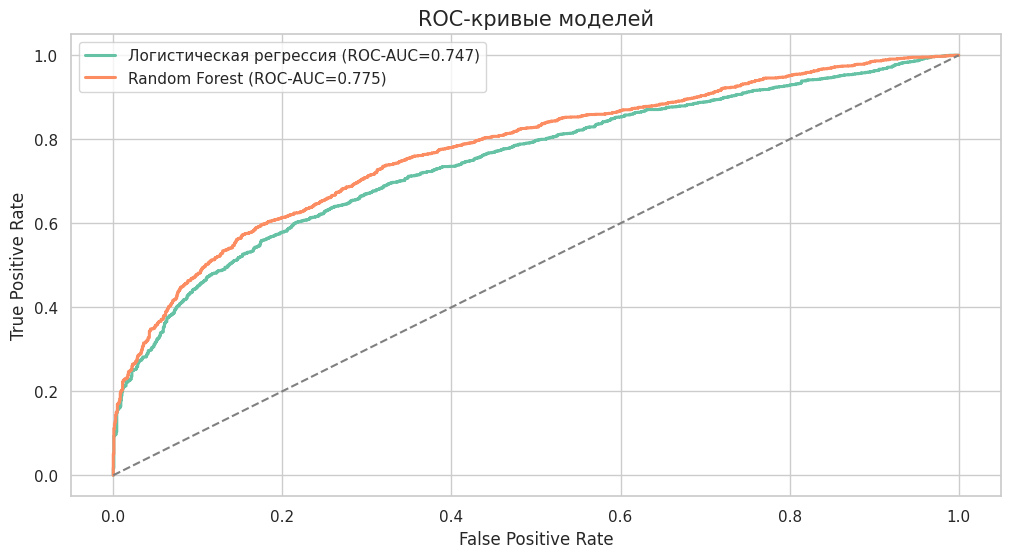

In [15]:
plot_model_roc_curves(ml_artifacts["roc_curves"]);

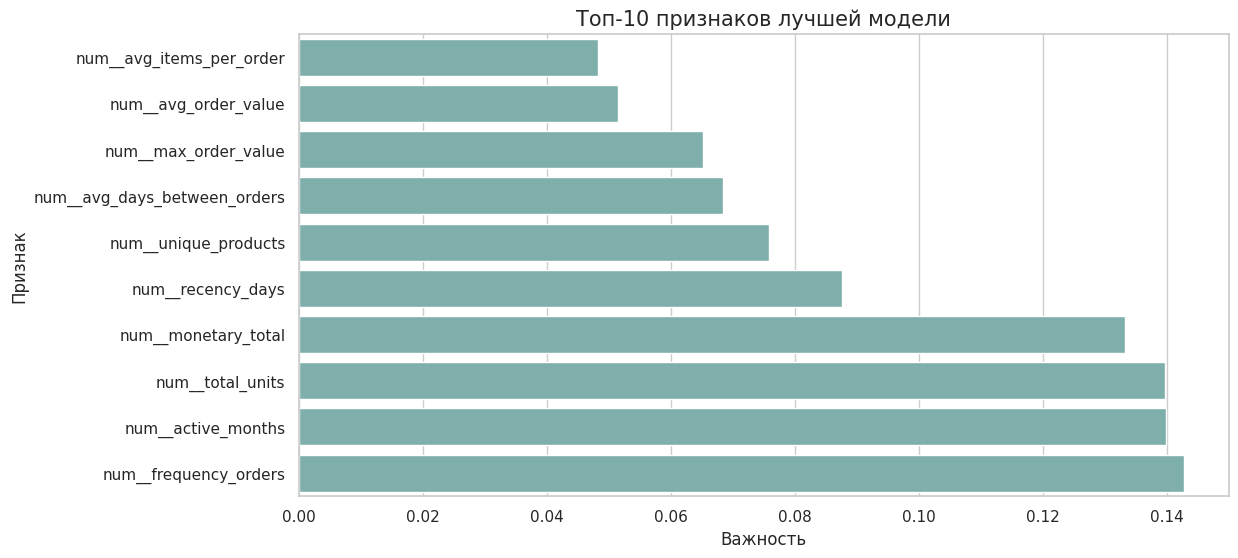

In [16]:
plot_feature_importance(ml_artifacts["feature_importance"]);

**Интерпретация:** модель показывает рабочий baseline-уровень качества. Это уже достаточно, чтобы ранжировать клиентскую базу по вероятности возврата и использовать прогноз как вход в CRM-механики, но недостаточно, чтобы воспринимать его как полностью автоматическое решение без дальнейшей калибровки.

## Выводы и рекомендации

1. Данные подтверждают выраженную неоднородность клиентской базы: небольшая доля клиентов приносит основную часть выручки.
2. Сегменты `Чемпионы` и `Лояльные` должны быть приоритетом для удержания и персональных предложений.
3. Сегменты `В зоне риска` и `Потерянные` подходят для реактивационных кампаний с ограниченным бюджетом и контролем окупаемости.
4. Когортный анализ показывает, что качество привлечения клиентов и первых заказов влияет на последующий retention.
5. Baseline ML-модель уже может использоваться для скоринга клиентов перед триггерными коммуникациями.

Практические действия для бизнеса:

- запустить отдельные сценарии удержания для high-value сегментов;
- тестировать welcome-цепочки для новых когорт;
- использовать прогноз повторной покупки как дополнительный приоритет в CRM;
- регулярно пересчитывать RFM и отслеживать переходы клиентов между сегментами.